In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import numpy as np
from sklearn.linear_model import LogisticRegression
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
%matplotlib inline

In [ ]:
train_url = "https://raw.githubusercontent.com/agconti/kaggle-titanic/master/data/train.csv"
test_url = "https://raw.githubusercontent.com/agconti/kaggle-titanic/master/data/test.csv"
train= pd.read_csv(train_url)
test= pd.read_csv(test_url)
print(train.shape)

(891, 12)


In [ ]:
print('info')
train.info()
print('isnull')
print(train.isnull().sum())
print('des')
display(train.describe())


info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
isnull
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtyp

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Survived
0    549
1    342
Name: count, dtype: int64


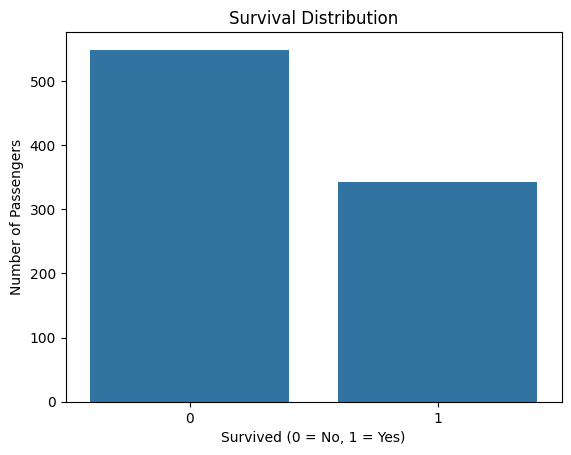

In [ ]:
plt.close()
print(train['Survived'].value_counts())

sns.countplot(data=train, x='Survived')

plt.title('Survival Distribution')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()


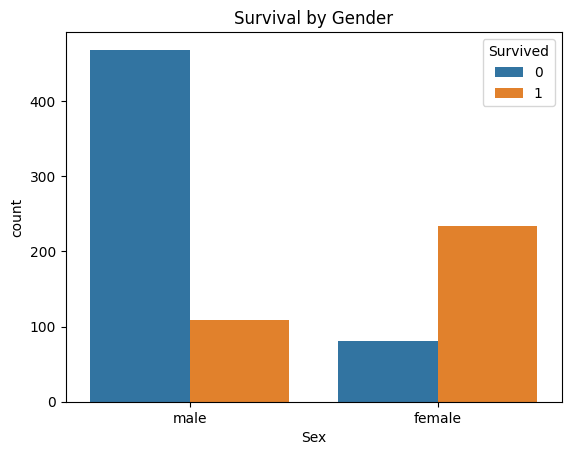

In [ ]:
plt.close()
sns.countplot(data=train, x='Sex', hue='Survived')
plt.title('Survival by Gender')
plt.show()


In [ ]:

survival_rate = train.groupby('Sex')['Survived'].mean()

print(survival_rate*100)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


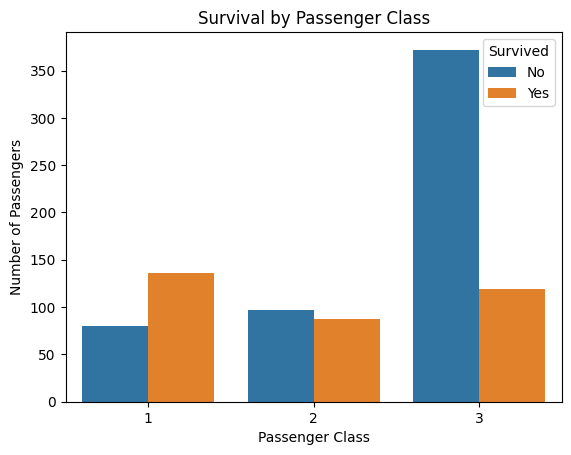

In [ ]:
sns.countplot(data=train, x='Pclass', hue='Survived')

plt.title('Survival by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')

plt.legend(title='Survived', labels=['No', 'Yes'])

plt.show()

In [ ]:
survival_class = train.groupby('Pclass')['Survived'].mean()

print((survival_class * 100).round(2))


Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


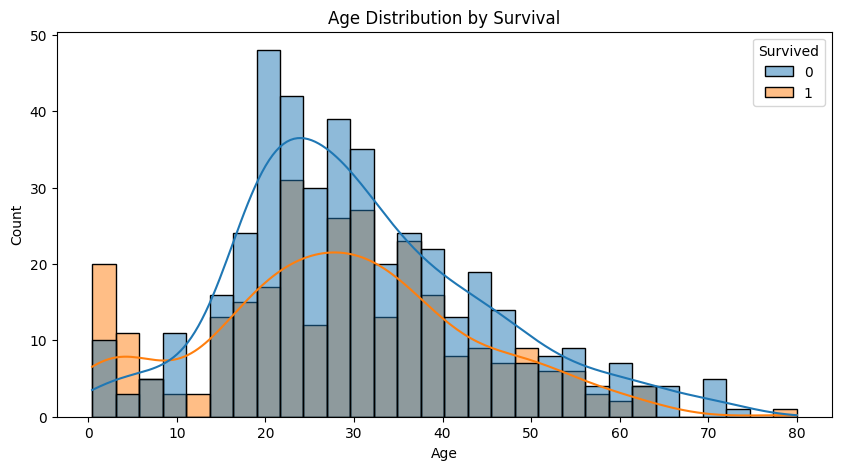

In [ ]:
plt.close()
plt.figure(figsize=(10, 5))

sns.histplot(data=train, x='Age', hue='Survived',
             bins=30, kde=True)

plt.title('Age Distribution by Survival')
plt.xlabel('Age')
plt.ylabel('Count')

plt.show()


In [ ]:
train['AgeGroup'] = pd.cut(
    train['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult',
            'Adult', 'Senior']
)

age_survival = train.groupby(
    'AgeGroup', observed=True
)['Survived'].mean()

print((age_survival * 100).round(2))


AgeGroup
Child          57.97
Teenager       42.86
Young Adult    38.27
Adult          40.00
Senior         22.73
Name: Survived, dtype: float64


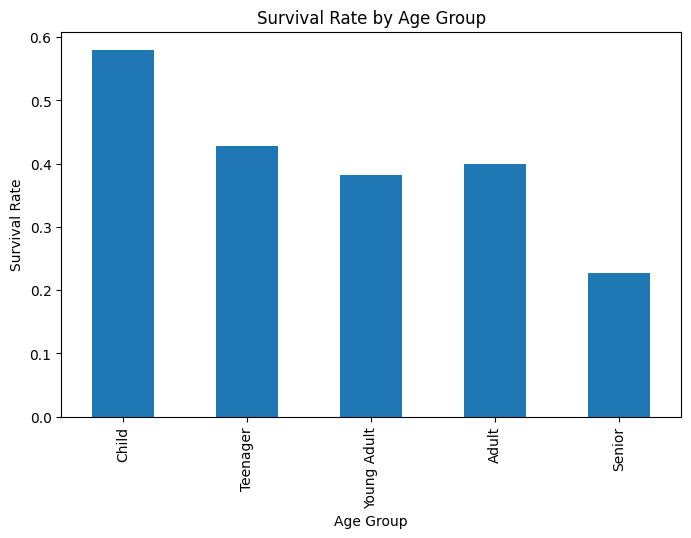

In [ ]:
age_survival.plot(kind='bar', figsize=(8, 5))

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')

plt.show()


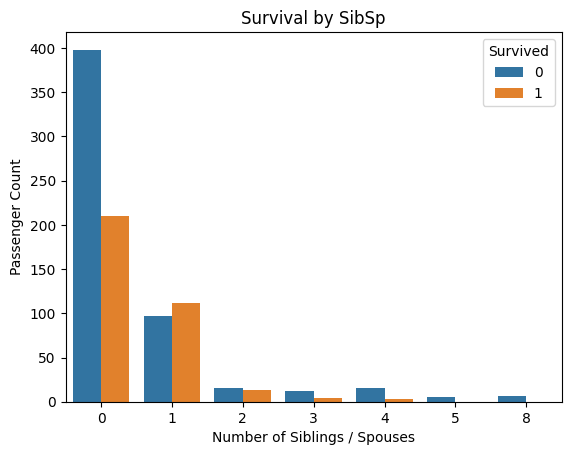

In [ ]:
sns.countplot(data=train, x='SibSp', hue='Survived')

plt.title('Survival by SibSp')
plt.xlabel('Number of Siblings / Spouses')
plt.ylabel('Passenger Count')

plt.show()


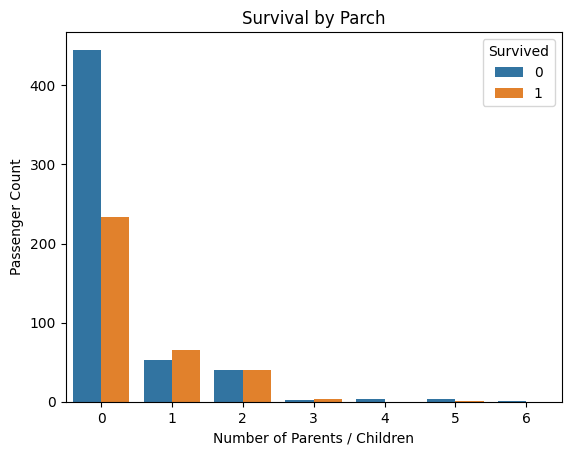

In [ ]:

sns.countplot(data=train, x='Parch', hue='Survived')

plt.title('Survival by Parch')
plt.xlabel('Number of Parents / Children')
plt.ylabel('Passenger Count')

plt.show()


In [ ]:

print("Survival Rate by SibSp:")

print(
    (train.groupby('SibSp')['Survived'].mean() * 100).round(2)
)

print("\nSurvival Rate by Parch:")

print(
    (train.groupby('Parch')['Survived'].mean() * 100).round(2)
)


Survival Rate by SibSp:
SibSp
0    34.54
1    53.59
2    46.43
3    25.00
4    16.67
5     0.00
8     0.00
Name: Survived, dtype: float64

Survival Rate by Parch:
Parch
0    34.37
1    55.08
2    50.00
3    60.00
4     0.00
5    20.00
6     0.00
Name: Survived, dtype: float64


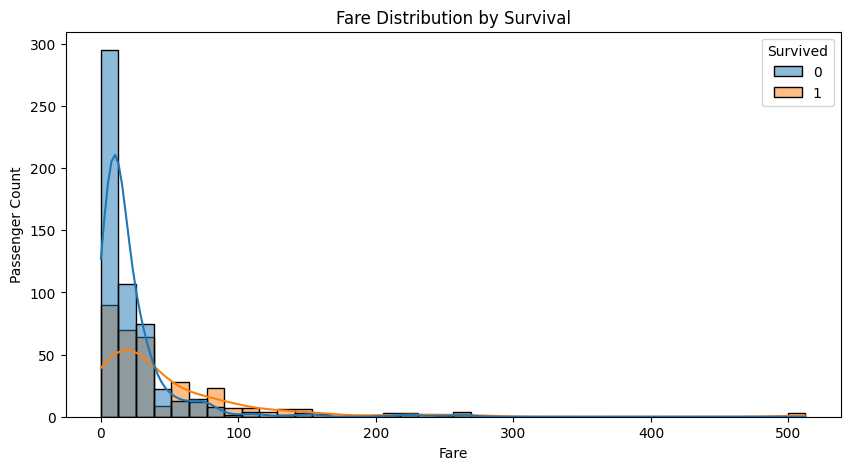

In [ ]:
plt.close()
plt.figure(figsize=(10, 5))

sns.histplot(data=train, x='Fare', hue='Survived',
             bins=40, kde=True)

plt.title('Fare Distribution by Survival')
plt.xlabel('Fare')
plt.ylabel('Passenger Count')

plt.show()


In [ ]:
fare_analysis = train.groupby('Survived')['Fare'].mean()
print(fare_analysis)

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64


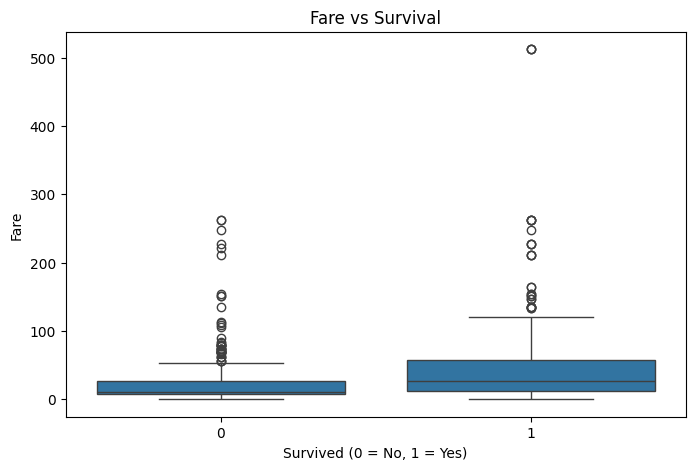

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=train, x='Survived', y='Fare')

plt.title('Fare vs Survival')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Fare')

plt.show()


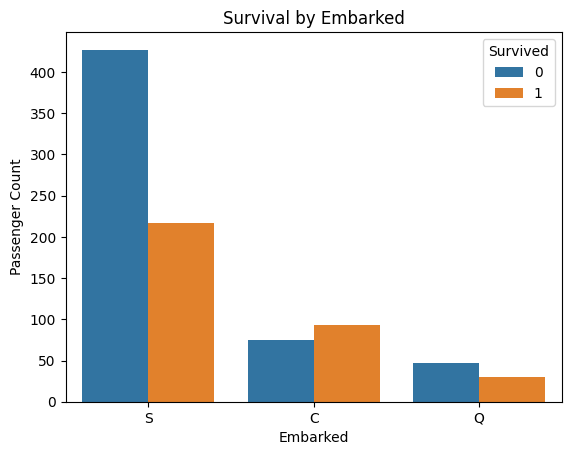

In [ ]:
sns.countplot(data=train, x='Embarked', hue='Survived')

plt.title('Survival by Embarked')
plt.xlabel('Embarked')
plt.ylabel('Passenger Count')

plt.show()


In [ ]:
embarked_survival = train.groupby('Embarked')['Survived'].mean()

print((embarked_survival * 100).round(2))


Embarked
C    55.36
Q    38.96
S    33.70
Name: Survived, dtype: float64


In [ ]:
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1
train['IsAlone'] = (train['FamilySize'] == 1).astype(int)
train['Title'] = train['Name'].str.extract(r',\s*([^.]*)\.')

display(train[['Name', 'FamilySize', 'IsAlone', 'Title']].head())


,Name,FamilySize,IsAlone,Title
0,"Braund, Mr. Owen Harris",2,0,Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",2,0,Mrs
2,"Heikkinen, Miss. Laina",1,1,Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",2,0,Mrs
4,"Allen, Mr. William Henry",1,1,Mr


In [ ]:

train['Deck'] = train['Cabin'].str[0].fillna('U')

train['Age'] = train['Age'].fillna(train['Age'].median())
train['Fare'] = train['Fare'].fillna(train['Fare'].median())
train['Embarked'] = train['Embarked'].fillna(train['Embarked'].mode()[0])


features = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
    'FamilySize', 'IsAlone', 'Embarked', 'Title', 'Deck'
]

train_ml = train[features + ['Survived']].copy()

display(train_ml.head())
print(train_ml.isnull().sum())


,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Embarked,Title,Deck,Survived
0,3,male,22.0,1,0,7.2500,2,0,S,Mr,U,0
1,1,female,38.0,1,0,71.2833,2,0,C,Mrs,C,1
2,3,female,26.0,0,0,7.9250,1,1,S,Miss,U,1
3,1,female,35.0,1,0,53.1000,2,0,S,Mrs,C,1
4,3,male,35.0,0,0,8.0500,1,1,S,Mr,U,0


Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
FamilySize    0
IsAlone       0
Embarked      0
Title         0
Deck          0
Survived      0
dtype: int64


In [ ]:

train_ml = pd.get_dummies(
    train_ml,
    columns=['Sex', 'Embarked', 'Title', 'Deck'],
    drop_first=True,
    dtype=int
)

display(train_ml.head())
print(train_ml.dtypes)


,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Survived,Sex_male,Embarked_Q,...,Title_Sir,Title_the Countess,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_U
0,3,22.0,1,0,7.2500,2,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
1,1,38.0,1,0,71.2833,2,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
2,3,26.0,0,0,7.9250,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,1
3,1,35.0,1,0,53.1000,2,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
4,3,35.0,0,0,8.0500,1,1,0,1,0,...,0,0,0,0,0,0,0,0,0,1


Pclass                  int64
Age                   float64
SibSp                   int64
Parch                   int64
Fare                  float64
FamilySize              int64
IsAlone                 int64
Survived                int64
Sex_male                int64
Embarked_Q              int64
Embarked_S              int64
Title_Col               int64
Title_Don               int64
Title_Dr                int64
Title_Jonkheer          int64
Title_Lady              int64
Title_Major             int64
Title_Master            int64
Title_Miss              int64
Title_Mlle              int64
Title_Mme               int64
Title_Mr                int64
Title_Mrs               int64
Title_Ms                int64
Title_Rev               int64
Title_Sir               int64
Title_the Countess      int64
Deck_B                  int64
Deck_C                  int64
Deck_D                  int64
Deck_E                  int64
Deck_F                  int64
Deck_G                  int64
Deck_T    

In [ ]:

from sklearn.model_selection import train_test_split

X = train_ml.drop('Survived', axis=1)
y = train_ml['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Object columns:", X_train.select_dtypes(include='object').columns.tolist())


X_train: (712, 34)
X_test: (179, 34)
Object columns: []


In [ ]:


model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

print("Model training completed.")


Model training completed.


Accuracy: 0.8380 (83.80%)

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87       110
           1       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



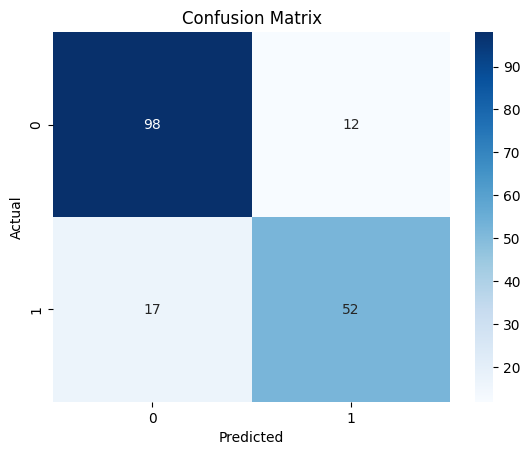

In [ ]:


y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


Random Forest Accuracy: 82.12 %

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       110
           1       0.82      0.68      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179



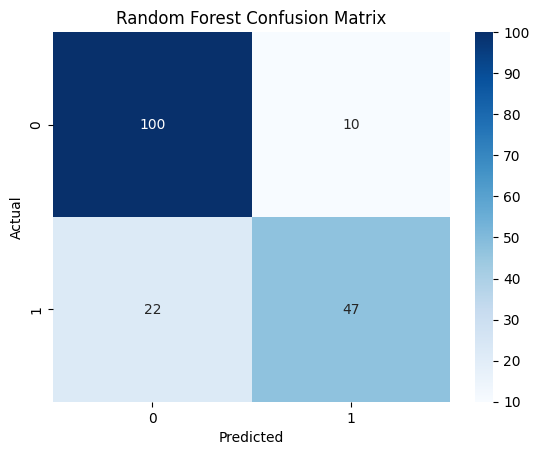

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    random_state=42
)


rf_model.fit(X_train, y_train)


rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))


cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


In [ ]:

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [5, 8, 12, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_

rf_pred_tuned = best_rf.predict(X_test)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nTuned Accuracy:")
print(round(accuracy_score(y_test, rf_pred_tuned) * 100, 2), "%")


Best Parameters:
{'max_depth': 12, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 500}

Tuned Accuracy:
80.45 %


In [ ]:
from sklearn.model_selection import cross_val_score

lr = LogisticRegression(max_iter=1000, random_state=42)

lr_scores = cross_val_score(
    lr, X_train, y_train,
    cv=5,
    scoring='accuracy'
)

rf_scores = cross_val_score(
    best_rf, X_train, y_train,
    cv=5,
    scoring='accuracy'
)

print("Logistic Regression CV:")
print(round(lr_scores.mean() * 100, 2), "%")

print("\nRandom Forest CV:")
print(round(rf_scores.mean() * 100, 2), "%")

Logistic Regression CV:
82.03 %

Random Forest CV:
83.01 %


In [ ]:
# آماده‌سازی دیتاست اصلی Kaggle test برای submission
# ساخت ویژگی‌ها مشابه train

test_ml = test.copy()

test_ml['FamilySize'] = test_ml['SibSp'] + test_ml['Parch'] + 1
test_ml['IsAlone'] = (test_ml['FamilySize'] == 1).astype(int)
test_ml['Title'] = test_ml['Name'].str.extract(r',\\s*([^.]*)\\.')

test_ml['Deck'] = test_ml['Cabin'].str[0].fillna('U')

# پر کردن مقادیر خالی با آمار دیتاست train
test_ml['Age'] = test_ml['Age'].fillna(train['Age'].median())
test_ml['Fare'] = test_ml['Fare'].fillna(train['Fare'].median())
test_ml['Embarked'] = test_ml['Embarked'].fillna(train['Embarked'].mode()[0])

features = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
    'FamilySize', 'IsAlone', 'Embarked', 'Title', 'Deck'
]

test_ml = test_ml[features].copy()

# تبدیل متغیرهای دسته‌ای به dummy
test_ml = pd.get_dummies(
    test_ml,
    columns=['Sex', 'Embarked', 'Title', 'Deck'],
    drop_first=True,
    dtype=int
)

# همسان کردن ستون‌ها و ترتیبشان با داده‌های آموزش
test_processed = test_ml.reindex(columns=X_train.columns, fill_value=0)

print("Training columns:", X_train.shape[1])
print("Competition test rows:", test_processed.shape[0])

# پیش‌بینی روی 418 مسافر فایل اصلی Kaggle test
test_pred = best_rf.predict(test_processed)

# ساخت فایل submission با PassengerId اصلی
submission = pd.DataFrame({
    'PassengerId': test['PassengerId'].values,
    'Survived': test_pred
})

submission.to_csv('submission.csv', index=False)

print(submission.shape)
display(submission.head())
print("\\nSubmission file created!")


Training columns: 34
Competition test rows: 418
(418, 2)


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


\nSubmission file created!
